# VLM – 01 Grounded text explanations (prototype)
**Purpose:** Turn the Model 2 decision into a short text explanation ("This is a LEG X-ray because…").
The ensemble (DeiT + MobileNetV3) decides; MobileNetV3 Grad-CAM shows where it looked; a ready-made VLM
(Qwen2-VL-2B-Instruct, not fine-tuned) writes the explanation from the X-ray + heatmap + prediction.
A rule-based template explanation is produced as a safe baseline.
**Inputs:** outputs/model2/ (cache_224.npz, mobilenetv3_model2_best.pt, preds_*_test.csv)
**Outputs:** outputs/vlm/ (explanations CSV, figures)

In [1]:
# ===== SETTINGS =====
from pathlib import Path

DRIVE_ROOT = Path('/content/drive/MyDrive/Research')
M2_DIR  = DRIVE_ROOT / 'outputs' / 'model2'
VLM_DIR = DRIVE_ROOT / 'outputs' / 'vlm'

SEED, IMG_SIZE = 42, 224
VLM_NAME = 'Qwen/Qwen2-VL-2B-Instruct'
VLM_IMG  = 448            # images are enlarged to 448 px for the VLM
LOW_CONF = 0.70           # below this confidence the explanation recommends human review

In [2]:
!pip install -q -U transformers accelerate grad-cam
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms as T
VLM_DIR.mkdir(parents=True, exist_ok=True)
device = 'cuda'

X = np.load(M2_DIR / 'cache_224.npz', allow_pickle=True)['images']
ens  = pd.read_csv(M2_DIR / 'preds_ensemble_top2_test.csv')
mb_p = pd.read_csv(M2_DIR / 'preds_mobilenetv3_test.csv')
dt_p = pd.read_csv(M2_DIR / 'preds_deit_small_test.csv')
ens['models_disagree'] = mb_p.pred_label.values != dt_p.pred_label.values
print('Test images:', len(ens), '| models disagree on', ens.models_disagree.sum())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 76.9 MB/s eta 0:00:00
Mounted at /content/drive
Test images: 519 | models disagree on 34


In [3]:
import torch.nn as nn
from torchvision.models import mobilenet_v3_large
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

ck = torch.load(M2_DIR / 'mobilenetv3_model2_best.pt', map_location=device)
CLASSES, SUPER = ck['classes'], ck['super']
SHORT = {c: c.split(' - ')[0] for c in CLASSES}
mb = mobilenet_v3_large(); mb.classifier[3] = nn.Linear(mb.classifier[3].in_features, len(CLASSES))
mb.load_state_dict(ck['state_dict']); mb.eval().to(device)
tf = T.Compose([T.ToTensor(), T.Lambda(lambda t: t.repeat(3, 1, 1)), T.Normalize(ck['mean'], ck['std'])])

def gradcam(ci, k):
    with GradCAM(model=mb, target_layers=[mb.features[-1]]) as cam:
        return cam(input_tensor=tf(Image.fromarray(X[ci])).unsqueeze(0).to(device),
                   targets=[ClassifierOutputTarget(k)])[0]

def rgb01(ci):
    return np.repeat(X[ci][..., None] / 255.0, 3, axis=2).astype(np.float32)

In [4]:
ANATOMY = {
    'Elbow to wrist':    'the radius and ulna (forearm bones)',
    'Foot and ankle':    'the ankle joint, tarsal and metatarsal bones',
    'Hip to knee':       'the pelvis/hip joint, femur or patella',
    'Knee to ankle':     'the tibia and fibula (lower-leg bones)',
    'OTHER':             'structures outside the limbs (e.g. ribs, lungs, spine or skull)',
    'Shoulder to elbow': 'the clavicle, scapula, shoulder joint or humerus',
    'Wrist and hand':    'the carpal, metacarpal and finger bones',
}

def cam_location(h):
    """Where is the hottest 10% of the heatmap? -> e.g. 'upper middle'."""
    yy, xx = np.nonzero(h >= np.quantile(h, 0.9))
    cy, cx = yy.mean() / h.shape[0], xx.mean() / h.shape[1]
    v = 'upper' if cy < 1/3 else 'lower' if cy > 2/3 else 'central'
    s = 'left' if cx < 1/3 else 'right' if cx > 2/3 else 'middle'
    return f'{v} {s}'

def template_text(r, h):
    cls = r.pred_label; p = r[f'p_{SHORT[cls]}']
    txt = (f'Classified as a {SUPER[cls]} X-ray, region "{SHORT[cls]}" (confidence {p:.0%}). '
           f'This region is characterised by {ANATOMY[SHORT[cls]]}. '
           f'The model\'s attention (Grad-CAM) is strongest in the {cam_location(h)} part of the image.')
    if p < LOW_CONF or r.models_disagree:
        txt += ' ⚠ Low confidence or model disagreement – human review recommended.'
    return txt

In [5]:
from transformers import AutoProcessor, AutoModelForImageTextToText

DTYPE = torch.float16          # if answers come out empty or garbled, change to torch.float32 and re-run
processor = AutoProcessor.from_pretrained(VLM_NAME, min_pixels=256 * 28 * 28, max_pixels=512 * 28 * 28)
vlm = AutoModelForImageTextToText.from_pretrained(VLM_NAME, torch_dtype=DTYPE).to(device).eval()

def ask_vlm(images, prompt, max_new_tokens=120):
    """Send one or more PIL images + a text prompt to the VLM, return its answer."""
    messages = [{'role': 'user', 'content': [{'type': 'image'} for _ in images] + [{'type': 'text', 'text': prompt}]}]
    text = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=[text], images=images, return_tensors='pt').to(device)
    with torch.no_grad():
        out = vlm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return processor.batch_decode(out[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()

print(ask_vlm([Image.fromarray(X[ens.cache_idx[0]]).convert('RGB').resize((VLM_IMG, VLM_IMG))],
              'Describe this image in one sentence.'))

preprocessor_config.json:   0%|          | 0.00/347 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


This is an X-ray image of a human arm, showing the bones of the forearm and hand.


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


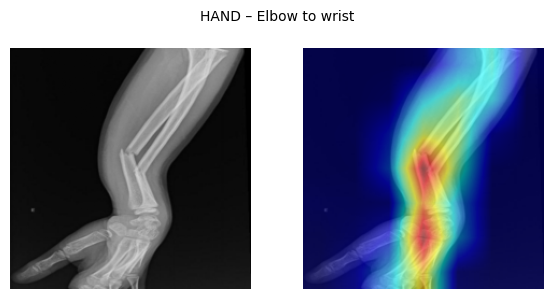

TEMPLATE: Classified as a HAND X-ray, region "Elbow to wrist" (confidence 93%). This region is characterised by the radius and ulna (forearm bones). The model's attention (Grad-CAM) is strongest in the central middle part of the image.
VLM     : The highlighted area in Image 2 shows a heatmap focusing on the elbow to wrist region of the X-ray. The AI classifier predicted that this area corresponds to the radius and ulna (forearm bones). The heatmap highlights the bones and structures visible in the X-ray, including the radius and ulna, which are clearly visible in the highlighted area. The classifier's confidence of 93% suggests that it is confident in its prediction.
----------------------------------------------------------------------------------------------------


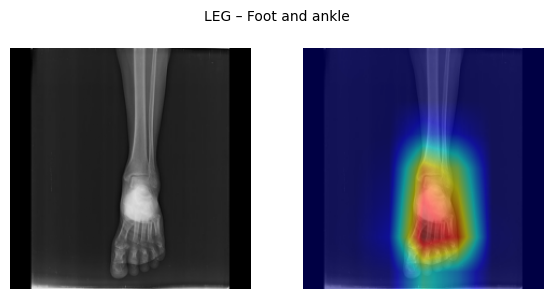

TEMPLATE: Classified as a LEG X-ray, region "Foot and ankle" (confidence 81%). This region is characterised by the ankle joint, tarsal and metatarsal bones. The model's attention (Grad-CAM) is strongest in the lower middle part of the image.
VLM     : The X-ray image shows a foot with the ankle joint, tarsal, and metatarsal bones clearly visible. The highlighted area, which is red/yellow, indicates areas of high concentration of calcium, which is typical of bone tissue. The ankle joint appears to be intact, and the tarsal and metatarsal bones are well-defined. The heatmap suggests that the AI classifier is focusing on the foot and ankle region, indicating that the bones and joints are the primary structures of interest.
----------------------------------------------------------------------------------------------------


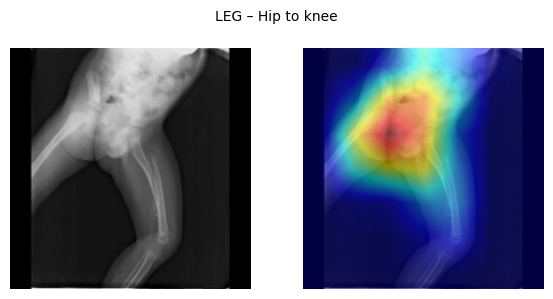

TEMPLATE: Classified as a LEG X-ray, region "Hip to knee" (confidence 99%). This region is characterised by the pelvis/hip joint, femur or patella. The model's attention (Grad-CAM) is strongest in the central middle part of the image.
VLM     : The highlighted area in Image 2 shows a heatmap focusing on the hip to knee region. The AI classifier predicted this area as the "Hip to knee" region, with a confidence of 99%. Visible bones and structures in this highlighted area include the femur (thigh bone), patella (kneecap), and the proximal femur (the upper part of the femur). The patella is highlighted in red/yellow, indicating that it is the most likely structure to be the focus of the AI classifier's prediction.
----------------------------------------------------------------------------------------------------


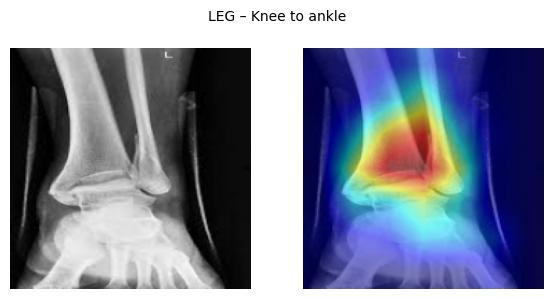

TEMPLATE: Classified as a LEG X-ray, region "Knee to ankle" (confidence 93%). This region is characterised by the tibia and fibula (lower-leg bones). The model's attention (Grad-CAM) is strongest in the central middle part of the image.
VLM     : The highlighted area in the heatmap shows a red/yellow color, indicating a high confidence score. This coloration suggests that the AI classifier focused on the knee to ankle region, specifically on the tibia and fibula bones. The highlighted area appears to be the lower leg bones, which are visible in the X-ray image. The tibia and fibula are the two main bones in the lower leg, and they are clearly visible in the highlighted area.
----------------------------------------------------------------------------------------------------


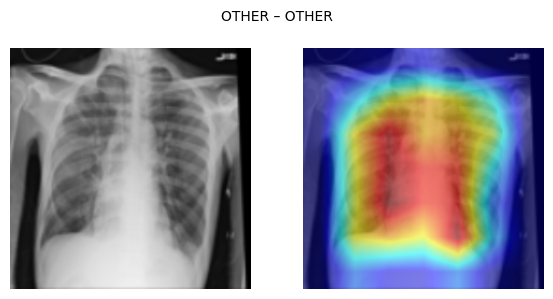

TEMPLATE: Classified as a OTHER X-ray, region "OTHER" (confidence 100%). This region is characterised by structures outside the limbs (e.g. ribs, lungs, spine or skull). The model's attention (Grad-CAM) is strongest in the central middle part of the image.
VLM     : The highlighted area in Image 2 shows a heatmap with red/yellow colors, indicating areas of high intensity. The AI classifier predicted "OTHER X-ray, body region 'OTHER' (structures outside the limbs (e.g. ribs, lungs, spine or skull))."

The visible bones and structures in the highlighted area include the ribs, which are the vertical, curved bones that form the protective cage of the thoracic cavity. The highlighted area also includes the spine, which runs vertically through the center of the thoracic cavity. The highlighted area does not show any clear signs of fractures, disease, or
----------------------------------------------------------------------------------------------------


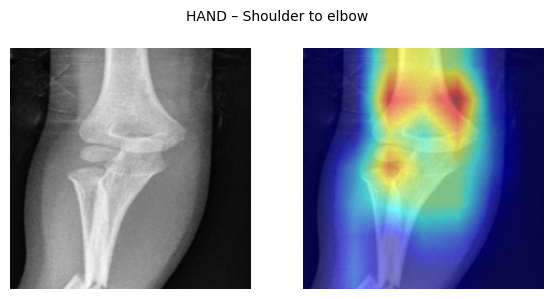

TEMPLATE: Classified as a HAND X-ray, region "Shoulder to elbow" (confidence 100%). This region is characterised by the clavicle, scapula, shoulder joint or humerus. The model's attention (Grad-CAM) is strongest in the upper middle part of the image.
VLM     : The highlighted area in Image 2 shows a heatmap with red/yellow colors concentrated around the clavicle, scapula, and shoulder joint. These areas are likely to be the bones and structures that the AI classifier predicted are relevant to the "Shoulder to elbow" region. The clavicle, scapula, and shoulder joint are visible in the X-ray, indicating that the classifier's prediction is accurate.
----------------------------------------------------------------------------------------------------


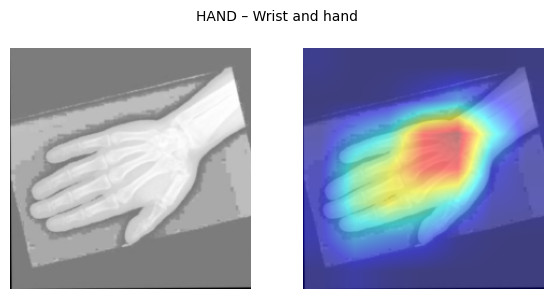

TEMPLATE: Classified as a HAND X-ray, region "Wrist and hand" (confidence 100%). This region is characterised by the carpal, metacarpal and finger bones. The model's attention (Grad-CAM) is strongest in the central middle part of the image.
VLM     : The AI classifier predicted that the highlighted area of the X-ray corresponds to the wrist and hand region. The visible bones and structures supporting this prediction include the carpal bones (which form the wrist joint), the metacarpal bones (which form the fingers), and the phalangeal bones (which form the fingers). The heatmap highlights these areas in red/yellow, indicating that the AI classifier is confident in its prediction.
----------------------------------------------------------------------------------------------------


In [6]:
def grounded_prompt(r):
    cls = r.pred_label; p = r[f'p_{SHORT[cls]}']
    return (f'Image 1 is an X-ray. Image 2 is the same X-ray with a heatmap: red/yellow areas show where an '
            f'AI classifier focused. The classifier predicted: {SUPER[cls]} X-ray, body region "{SHORT[cls]}" '
            f'({ANATOMY[SHORT[cls]]}), confidence {p:.0%}. In 2-3 short sentences, explain which visible bones or '
            f'structures support this prediction, referring to the highlighted area. Only describe what is visible. '
            f'If the image does not clearly support the prediction, say so. Do not diagnose fractures or disease.')

examples = ens[ens.label == ens.pred_label].groupby('pred_label').sample(1, random_state=SEED)
rows = []
for _, r in examples.iterrows():
    k = CLASSES.index(r.pred_label)
    h = gradcam(r.cache_idx, k)
    overlay = show_cam_on_image(rgb01(r.cache_idx), h, use_rgb=True)
    img1 = Image.fromarray(X[r.cache_idx]).convert('RGB').resize((VLM_IMG, VLM_IMG))
    img2 = Image.fromarray(overlay).resize((VLM_IMG, VLM_IMG))
    t_txt, v_txt = template_text(r, h), ask_vlm([img1, img2], grounded_prompt(r))
    rows.append({'filename': r.filename, 'true': r.label, 'pred': r.pred_label, 'template': t_txt, 'vlm': v_txt})

    fig, ax = plt.subplots(1, 2, figsize=(6, 3))
    ax[0].imshow(rgb01(r.cache_idx)); ax[1].imshow(overlay)
    for a in ax: a.axis('off')
    plt.suptitle(f'{SUPER[r.pred_label]} – {SHORT[r.pred_label]}', fontsize=10); plt.tight_layout(); plt.show()
    print('TEMPLATE:', t_txt); print('VLM     :', v_txt); print('-' * 100)

pd.DataFrame(rows).to_csv(VLM_DIR / 'explanations_examples.csv', index=False)

### Findings – first VLM attempt
Fluent, but: echoes the anatomy list from the prompt, misreads the heatmap (as "calcium" / "confidence"),
anatomical errors (metacarpals "form the fingers"), overclaims ("prediction is accurate"), ignores "no fractures".
→ (1) measure what the VLM can see WITHOUT being told the answer (blind test); (2) improved prompt without the anatomy list.

In [7]:
OPTIONS = {'A': 'Shoulder to elbow', 'B': 'Elbow to wrist', 'C': 'Wrist and hand', 'D': 'Hip to knee',
           'E': 'Knee to ankle', 'F': 'Foot and ankle', 'G': 'OTHER'}
BLIND_PROMPT = ('This is an X-ray. Which body region does it mainly show? Options: '
                'A) shoulder to elbow (upper arm), B) elbow to wrist (forearm), C) wrist and hand, '
                'D) hip to knee (thigh), E) knee to ankle (lower leg), F) foot and ankle, '
                'G) other (chest, spine, skull, etc.). Answer with the letter only.')
SHORT2CLS = {SHORT[c]: c for c in CLASSES}

blind = ens.groupby('label').sample(10, random_state=SEED)
answers = []
for _, r in blind.iterrows():
    a = ask_vlm([Image.fromarray(X[r.cache_idx]).convert('RGB').resize((VLM_IMG, VLM_IMG))], BLIND_PROMPT, max_new_tokens=5)
    letter = next((ch for ch in a.upper() if ch in OPTIONS), None)
    answers.append(SHORT2CLS[OPTIONS[letter]] if letter else 'NO ANSWER')
blind['vlm_pred'] = answers

acc7_vlm = (blind.vlm_pred == blind.label).mean()
acc3_vlm = (blind.vlm_pred.map(SUPER) == blind.label.map(SUPER)).mean()
acc7_ens = (blind.pred_label == blind.label).mean()
acc3_ens = (blind.pred_super == blind.label.map(SUPER)).mean()
print(f'On the same {len(blind)} test images:')
print(f'  VLM alone (no hints) : 7-class {acc7_vlm:.1%} | HAND/LEG/OTHER {acc3_vlm:.1%}')
print(f'  Our ensemble         : 7-class {acc7_ens:.1%} | HAND/LEG/OTHER {acc3_ens:.1%}')
print('\nVLM answers per true class:')
print(pd.crosstab(blind.label.map(SHORT), blind.vlm_pred.map(lambda c: SHORT.get(c, c))))
blind.to_csv(VLM_DIR / 'vlm_blind_test.csv', index=False)

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


On the same 70 test images:
  VLM alone (no hints) : 7-class 74.3% | HAND/LEG/OTHER 95.7%
  Our ensemble         : 7-class 85.7% | HAND/LEG/OTHER 95.7%

VLM answers per true class:
vlm_pred           Elbow to wrist  Foot and ankle  Hip to knee  Knee to ankle  \
label                                                                           
Elbow to wrist                  9               0            0              0   
Foot and ankle                  0              10            0              0   
Hip to knee                     1               0            2              7   
Knee to ankle                   0               4            0              6   
OTHER                           1               0            0              0   
Shoulder to elbow               3               0            0              0   
Wrist and hand                  0               0            0              0   

vlm_pred           OTHER  Shoulder to elbow  Wrist and hand  
label                      

In [8]:
def grounded_prompt_v2(r):
    cls = r.pred_label
    return (f'Image 1 is an X-ray. Image 2 is the same X-ray with a coloured overlay showing where an AI '
            f'classifier looked (the colours are NOT bone density and NOT confidence). '
            f'The classifier predicted the body region "{SHORT[cls]}" ({SUPER[cls]}).\n'
            f'Step 1: Name the bones you can actually see inside the red/yellow area.\n'
            f'Step 2: In one sentence, say whether those bones are consistent with "{SHORT[cls]}".\n'
            f'Answer in exactly this format:\nVisible bones: ...\nConsistency: ...\n'
            f'Do not mention fractures, disease or confidence.')

rows2 = []
for _, r in examples.iterrows():
    k = CLASSES.index(r.pred_label)
    overlay = show_cam_on_image(rgb01(r.cache_idx), gradcam(r.cache_idx, k), use_rgb=True)
    img1 = Image.fromarray(X[r.cache_idx]).convert('RGB').resize((VLM_IMG, VLM_IMG))
    img2 = Image.fromarray(overlay).resize((VLM_IMG, VLM_IMG))
    v2 = ask_vlm([img1, img2], grounded_prompt_v2(r), max_new_tokens=100)
    rows2.append({'filename': r.filename, 'pred': r.pred_label, 'vlm_v2': v2})
    print(f'== {SHORT[r.pred_label]} ==\n{v2}\n')
pd.DataFrame(rows2).to_csv(VLM_DIR / 'explanations_examples_v2.csv', index=False)

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


== Elbow to wrist ==
Visible bones: Radius, Ulna, Humerus, Fingers
Consistency: Yes, the bones are consistent with "Elbow to wrist".

== Foot and ankle ==
Visible bones: Calcaneus, talus, navicular, cuboid, metatarsals
Consistency: Yes

== Hip to knee ==
Visible bones: Femur, Tibia, Fibula
Consistency: Yes

== Knee to ankle ==
Visible bones: Tibia, fibula, tarsal bones
Consistency: Yes, the visible bones are consistent with "Knee to ankle".

== OTHER ==
Visible bones: Clavicles, ribs
Consistency: Consistent with "OTHER"

== Shoulder to elbow ==
Visible bones: Radius, Ulna
Consistency: Yes

== Wrist and hand ==
Visible bones: Radius, Ulna, Wrist bones
Consistency: Yes, the bones visible in the red/yellow area are consistent with the wrist and hand region.



### Findings – blind test + v2 prompt
Blind (70 test images, 10/class): VLM 7-class 74.3%, HAND/LEG/OTHER 95.7% vs ensemble 85.7% / 95.7%.
VLM strong at coarse level, weak at fine leg regions (Hip-to-knee → Knee-to-ankle 7/10).
v2 prompt: concise, no echo, but VLM answers "consistent" even when its own bones contradict (sycophancy).
→ Final design: ensemble decides; template always shown; VLM used as an INDEPENDENT blind check at
HAND/LEG/OTHER level – agreement adds its description (unverified), disagreement triggers human review.

In [9]:
agree = blind.vlm_pred.map(SUPER) == blind.pred_super
wrong = blind.pred_super != blind.label.map(SUPER)
print(f'VLM agrees with the ensemble (HAND/LEG/OTHER) on {agree.mean():.1%} of the 70 images')
print(f'Ensemble errors: {wrong.sum()} | caught by VLM disagreement: {(wrong & ~agree).sum()}')
print(f'Correct ensemble answers flagged anyway (false alarms): {(~wrong & ~agree).sum()}')

VLM agrees with the ensemble (HAND/LEG/OTHER) on 94.3% of the 70 images
Ensemble errors: 3 | caught by VLM disagreement: 2
Correct ensemble answers flagged anyway (false alarms): 2


In [10]:
def vlm_blind_region(ci):
    a = ask_vlm([Image.fromarray(X[ci]).convert('RGB').resize((VLM_IMG, VLM_IMG))], BLIND_PROMPT, max_new_tokens=5)
    letter = next((ch for ch in a.upper() if ch in OPTIONS), None)
    return SHORT2CLS[OPTIONS[letter]] if letter else None

def final_explanation(r):
    cls = r.pred_label; k = CLASSES.index(cls)
    h = gradcam(r.cache_idx, k)
    overlay = show_cam_on_image(rgb01(r.cache_idx), h, use_rgb=True)
    text = template_text(r, h)
    vlm_cls = vlm_blind_region(r.cache_idx)                       # independent check, no hints
    if vlm_cls is not None and SUPER[vlm_cls] == SUPER[cls]:
        img1 = Image.fromarray(X[r.cache_idx]).convert('RGB').resize((VLM_IMG, VLM_IMG))
        img2 = Image.fromarray(overlay).resize((VLM_IMG, VLM_IMG))
        desc = ask_vlm([img1, img2], grounded_prompt_v2(r), max_new_tokens=100).split('Consistency')[0].strip()
        text += (f' Independent check: a vision-language model (not told the answer) also sees a {SUPER[cls]} X-ray. '
                 f'AI description (unverified): {desc}')
    else:
        text += f' ⚠ Independent check disagrees (VLM says: {SHORT.get(vlm_cls, "no answer")}) – human review recommended.'
    return text, overlay

demo = pd.concat([examples, ens[ens.models_disagree].sample(3, random_state=SEED)])   # 7 normal + 3 difficult cases
rows3 = []
for _, r in demo.iterrows():
    text, overlay = final_explanation(r)
    rows3.append({'filename': r.filename, 'true': r.label, 'pred': r.pred_label, 'explanation': text})
    print(f'[TRUE: {SHORT[r.label]} | PRED: {SHORT[r.pred_label]}]\n{text}\n')
pd.DataFrame(rows3).to_csv(VLM_DIR / 'final_explanations.csv', index=False)

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[TRUE: Elbow to wrist | PRED: Elbow to wrist]
Classified as a HAND X-ray, region "Elbow to wrist" (confidence 93%). This region is characterised by the radius and ulna (forearm bones). The model's attention (Grad-CAM) is strongest in the central middle part of the image. Independent check: a vision-language model (not told the answer) also sees a HAND X-ray. AI description (unverified): Visible bones: Radius, Ulna, Humerus, Fingers

[TRUE: Foot and ankle | PRED: Foot and ankle]
Classified as a LEG X-ray, region "Foot and ankle" (confidence 81%). This region is characterised by the ankle joint, tarsal and metatarsal bones. The model's attention (Grad-CAM) is strongest in the lower middle part of the image. Independent check: a vision-language model (not told the answer) also sees a LEG X-ray. AI description (unverified): Visible bones: Calcaneus, talus, navicular, cuboid, metatarsals

[TRUE: Hip to knee | PRED: Hip to knee]
Classified as a LEG X-ray, region "Hip to knee" (confidence 99%

## Summary – VLM prototype (grounded explanations)
**Design:** Ensemble (DeiT + MobileNetV3) decides → MobileNetV3 Grad-CAM shows where → rule-based template explanation
(always shown, factual) → Qwen2-VL-2B-Instruct (ready-made, not fine-tuned) used as an INDEPENDENT blind check:
agreement adds its bone description (labelled unverified); disagreement, low confidence (<70%) or ensemble-member
disagreement → "human review recommended".
**Findings:**
- First prompt: fluent but echoed the prompt, misread the heatmap ("calcium", "confidence"), anatomical errors, overclaiming.
- Blind test (70 test images, 10/class): VLM 7-class 74.3%, HAND/LEG/OTHER 95.7% (ensemble 85.7% / 95.7%);
  weak on fine leg regions (Hip-to-knee → Knee-to-ankle 7/10).
- v2 prompt: concise, but VLM always answers "consistent" (sycophancy) → its self-judgement is not used.
- As independent check: agrees 94.3%; caught 2/3 ensemble errors; 2/70 false alarms (small sample).
- 3 hard cases (models disagree): all flagged for review; 2 were errors, both within the correct HAND/LEG group.
**Limitations / future work:** VLM descriptions still contain anatomical errors → medical fine-tuning (e.g. on
region-labelled X-ray/caption pairs) or a medical VLM; VLM is large (4.4 GB) and slow (seconds/image) vs classifier (18 ms).
Outputs: outputs/vlm/ (explanations_examples*.csv, vlm_blind_test.csv, final_explanations.csv).